***A/B Test - Statistical Analysis***

### Гипотезы для Retention D7

**H₀ — нулевая гипотеза:** Retention D7 в группах A и B одинакова.

$$
H_0: p_A = p_B
$$

**H₁ — альтернативная гипотеза:** Retention D7 в группах A и B различается.

$$
H_1: p_A \neq p_B
$$

In [1]:
import pandas as pd

ab_events = pd.read_csv("../data/ab_events_clean.csv")

ab_events

,user_id,group,signup_date,grade,timestamp,event_type
0,U300000,B,2026-03-09,5,2026-05-04 19:36:00,login
1,U300000,B,2026-03-09,5,2026-05-07 19:35:00,login
2,U300000,B,2026-03-09,5,2026-05-07 19:42:00,homework_started
3,U300000,B,2026-03-09,5,2026-05-08 17:05:00,login
4,U300000,B,2026-03-09,5,2026-05-08 17:11:00,homework_started
...,...,...,...,...,...,...
179106,U305999,A,2025-06-19,11,2026-05-20 19:56:00,homework_started
179107,U305999,A,2025-06-19,11,2026-05-20 20:16:00,homework_completed
179108,U305999,A,2025-06-19,11,2026-05-21 20:47:00,login
179109,U305999,A,2025-06-19,11,2026-05-21 20:53:00,homework_started


In [2]:
return_visit_d7 = (
    ab_events[ab_events['event_type'] == 'return_visit_d7']
    .groupby('group')['user_id']
    .nunique()
)

total_users = (
    ab_events.groupby('group')['user_id']
    .nunique()
)

print('Вернувшиеся пользователи D7:')
print(return_visit_d7)

print('\nВсего пользователей:')
print(total_users)

Вернувшиеся пользователи D7:
group
A    2179
B    2335
Name: user_id, dtype: int64

Всего пользователей:
group
A    2997
B    2995
Name: user_id, dtype: int64


### Выбор статистического критерия

Для сравнения Retention D7, Retention D14 и Conversion между контрольной и тестовой группами используется z-тест двух пропорций (`proportions_ztest` из `statsmodels`).

Выбор обусловлен бинарной природой пользовательских метрик: каждый пользователь либо совершил целевое действие, либо нет. Размеры групп достаточны для применения нормальной аппроксимации при предположении независимости наблюдений.

Для каждой метрики проверяется двусторонняя гипотеза:

- **H₀:** pA = pB - доли пользователей в группах равны.
- **H₁:** pA ≠ pB - доли пользователей различаются.

Уровень значимости α = 0,05 определяет допустимый риск ошибки I рода. Мощность теста (1 - β) связана с риском ошибки II рода и используется при оценке минимального обнаруживаемого эффекта (MDE).

Поскольку одновременно анализируются три продуктовые метрики, для контроля семейной вероятности ошибки I рода применяется поправка Холма.

**Ограничения:** анализ проводится на завершённой выгрузке эксперимента; отсутствие промежуточных проверок значимости во время проведения теста подтвердить невозможно. Метрика Conversion отражает завершение хотя бы одного домашнего задания, а не полное прохождение курса, поскольку отдельное событие завершения курса в данных отсутствует.

In [3]:
from statsmodels.stats.proportion import proportions_ztest

# Количество вернувшихся пользователей
successes = [
    return_visit_d7['B'],
    return_visit_d7['A']
]

# Общее количество пользователей
observations = [
    total_users['B'],
    total_users['A']
]

z_stat, p_value = proportions_ztest(
    count=successes,
    nobs=observations,
    alternative='two-sided'
)

print(f'Z-statistic: {z_stat:.4f}')
print(f'P-value: {p_value:.8f}')

Z-statistic: 4.7203
P-value: 0.00000236


Обнаружено статистически значимое различие Retention D7 между группами A и B. Наблюдаемое удержание в B выше на 5,26 процентного пункта.

### Гипотезы для Retention D14

**H₀ — нулевая гипотеза:** Retention D14 в группах A и B одинакова.

$$
H_0: p_A = p_B
$$

**H₁ — альтернативная гипотеза:** Retention D14 в группах A и B различается.

$$
H_1: p_A \neq p_B
$$

In [4]:
return_visit_d14 = (
    ab_events[ab_events['event_type'] == 'return_visit_d14']
    .groupby('group')['user_id']
    .nunique()
)

z_d14, p_d14 = proportions_ztest(
    count=[return_visit_d14['B'], return_visit_d14['A']],
    nobs=[total_users['B'], total_users['A']],
    alternative='two-sided'
)

print(f'Z-statistic: {z_d14:.4f}')
print(f'P-value: {p_d14:.10f}')

Z-statistic: 6.1690
P-value: 0.0000000007


### Гипотезы для Conversion to First Homework Completion

**H₀ — нулевая гипотеза:** Conversion to First Homework Completion в группах A и B одинакова.

$$
H_0: p_A = p_B
$$

**H₁ — альтернативная гипотеза:** Conversion to First Homework Completion в группах A и B различается.

$$
H_1: p_A \neq p_B
$$

In [5]:
completed_users = (
    ab_events[ab_events['event_type'] == 'homework_completed']
    .groupby('group')['user_id']
    .nunique()
)

z_cr, p_cr = proportions_ztest(
    count=[completed_users['B'], completed_users['A']],
    nobs=[total_users['B'], total_users['A']],
    alternative='two-sided'
)

print(f'Z-statistic: {z_cr:.4f}')
print(f'P-value: {p_cr:.8f}')

Z-statistic: 3.5245
P-value: 0.00042427


Все три различия статистически значимы при α = 0,05 в рамках использованных тестов.

In [6]:
from statsmodels.stats.proportion import confint_proportions_2indep

metrics = {
    'Retention D7': return_visit_d7,
    'Retention D14': return_visit_d14,
    'Conversion': completed_users
}

for name, counts in metrics.items():
    ci_low, ci_high = confint_proportions_2indep(
        count1=counts['B'],
        nobs1=total_users['B'],
        count2=counts['A'],
        nobs2=total_users['A'],
        compare='diff',
        method='newcomb',
        alpha=0.05
    )

    print(
        f'{name}: 95% CI = '
        f'[{ci_low * 100:.2f}; {ci_high * 100:.2f}] п.п.'
    )

Retention D7: 95% CI = [3.08; 7.43] п.п.
Retention D14: 95% CI = [5.10; 9.82] п.п.
Conversion: 95% CI = [0.54; 1.89] п.п.


Все интервалы находятся выше нуля. Это согласуется с результатами z-тестов: по всем трём показателям наблюдается положительное статистически значимое различие.

In [7]:
# возьмём мощность 80%, уровень значимости 5% и поправку Бонферрони для трёх метрик

import numpy as np
from statsmodels.stats.power import NormalIndPower

power_analysis = NormalIndPower()

n_A = total_users['A']
n_B = total_users['B']

mde_h = power_analysis.solve_power(
    effect_size=None,
    nobs1=n_B,
    alpha=0.05 / 3,
    power=0.80,
    ratio=n_A / n_B,
    alternative='two-sided'
)

baseline = {
    'Retention D7': return_visit_d7['A'] / n_A,
    'Retention D14': return_visit_d14['A'] / n_A,
    'Conversion': completed_users['A'] / n_A
}

for name, p_A in baseline.items():
    p_B_min = np.sin(
        np.arcsin(np.sqrt(p_A)) + mde_h / 2
    ) ** 2

    mde_pp = (p_B_min - p_A) * 100

    print(f'{name}: MDE = {mde_pp:.2f} п.п.')

Retention D7: MDE = 3.64 п.п.
Retention D14: MDE = 3.85 п.п.
Conversion: MDE = 1.10 п.п.


In [8]:
events_per_user = (
    ab_events.groupby('user_id')['event_type']
    .count()
)

extreme_users = events_per_user[
    events_per_user > 500
].index

print('Экстремально активных пользователей:', len(extreme_users))

Экстремально активных пользователей: 12


In [9]:
ab_events_no_extreme = ab_events[
    ~ab_events['user_id'].isin(extreme_users)
].copy()

print('Пользователей до исключения экстремально активных пользователей:', ab_events['user_id'].nunique())
print('Пользователей после:', ab_events_no_extreme['user_id'].nunique())

Пользователей до исключения экстремально активных пользователей: 5992
Пользователей после: 5980


In [10]:
total_no_extreme = (
    ab_events_no_extreme.groupby('group')['user_id']
    .nunique()
)

metrics_no_extreme = {}

for name, event in {
    'Retention D7': 'return_visit_d7',
    'Retention D14': 'return_visit_d14',
    'Conversion': 'homework_completed'
}.items():

    counts = (
        ab_events_no_extreme[
            ab_events_no_extreme['event_type'] == event
        ]
        .groupby('group')['user_id']
        .nunique()
    )

    rates = counts.reindex(['A', 'B'], fill_value=0) / total_no_extreme.reindex(['A', 'B']) * 100

    metrics_no_extreme[name] = {
        'A (%)': rates['A'],
        'B (%)': rates['B'],
        'B - A (pp)': rates['B'] - rates['A']
    }

sensitivity_summary = pd.DataFrame(metrics_no_extreme).T

sensitivity_summary.round(2)

,A (%),B (%),B - A (pp)
Retention D7,72.69,77.98,5.28
Retention D14,28.81,36.24,7.43
Conversion,97.63,98.83,1.20


In [11]:
original_effects = pd.Series({
    'Retention D7': (
        return_visit_d7['B'] / total_users['B']
        - return_visit_d7['A'] / total_users['A']
    ) * 100,

    'Retention D14': (
        return_visit_d14['B'] / total_users['B']
        - return_visit_d14['A'] / total_users['A']
    ) * 100,

    'Conversion': (
        completed_users['B'] / total_users['B']
        - completed_users['A'] / total_users['A']
    ) * 100
})

comparison = pd.DataFrame({
    'Original effect (pp)': original_effects,
    'Without extreme users (pp)': sensitivity_summary['B - A (pp)']
})

comparison['Change (pp)'] = (
    comparison['Without extreme users (pp)']
    - comparison['Original effect (pp)']
)

comparison.round(3)

,Original effect (pp),Without extreme users (pp),Change (pp)
Retention D7,5.257,5.285,0.027
Retention D14,7.465,7.435,-0.030
Conversion,1.200,1.202,0.001


Вывод: исключение 12 экстремально активных пользователей практически не изменило три основные метрики.

### Sensitivity Analysis - вывод

Для оценки устойчивости результатов проведён повторный расчёт продуктовых метрик после исключения 12 пользователей с более чем 500 событиями.

Изменения эффекта 'B - A' составили менее 0,04 процентного пункта по каждой из трёх метрик.

Таким образом, наблюдаемые различия в пользовательской конверсии и Retention D7/D14 практически не зависят от экстремально активных пользователей. Основной анализ сохранён на полной очищенной выборке.

Сегментация по классам (grade):

In [12]:
grade_distribution = (
    ab_events.groupby(['grade', 'group'])['user_id']
    .nunique()
    .unstack('group', fill_value=0)
)

grade_distribution

group,A,B
grade,,
5,446,416
6,447,465
7,403,437
8,454,432
9,431,379
10,410,438
11,406,428


In [13]:
d7_by_grade = (
    ab_events[
        ab_events['event_type'] == 'return_visit_d7'
    ]
    .groupby(['grade', 'group'])['user_id']
    .nunique()
    .unstack('group', fill_value=0)
)

retention_d7_by_grade = (
    d7_by_grade / grade_distribution * 100
)

retention_d7_by_grade['B - A (pp)'] = (
    retention_d7_by_grade['B']
    - retention_d7_by_grade['A']
)

retention_d7_by_grade.round(2)

group,A,B,B - A (pp)
grade,,,
5,72.87,82.45,9.58
6,75.62,86.45,10.84
7,70.72,84.44,13.72
8,73.57,77.55,3.98
9,71.69,78.36,6.67
10,71.22,69.86,-1.36
11,72.91,66.12,-6.78


5–7 классы: сильный положительный эффект, от +9,58 до +13,72 п.п. Максимальное улучшение - в 7-м классе.



8–9 классы: положительный, но более умеренный эффект - +3,98 и +6,67 п.п.



10–11 классы: отрицательный наблюдаемый эффект - -1,36 и −6,78 п.п.

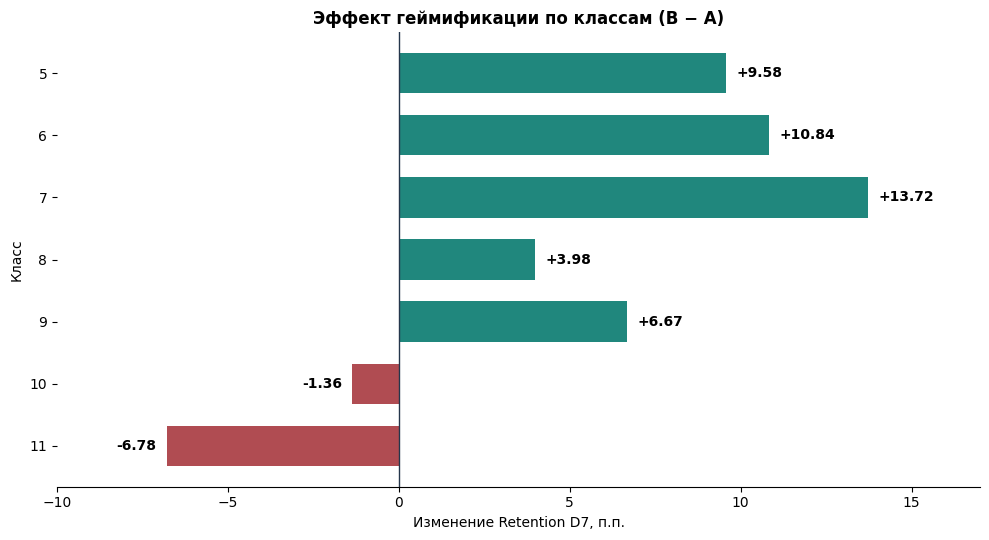

In [29]:
from pathlib import Path
import matplotlib.pyplot as plt

Path("../images").mkdir(exist_ok=True)

effect = retention_d7_by_grade["B - A (pp)"].sort_index()

colors = [
    "#20877D" if value >= 0 else "#B04C52"
    for value in effect
]

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(
    effect.index.astype(str),
    effect.values,
    color=colors,
    height=0.65
)

ax.invert_yaxis()
ax.axvline(0, color="#24364B", linewidth=1)
ax.set_xlim(-10, 17)
ax.set_xlabel("Изменение Retention D7, п.п.")
ax.set_ylabel("Класс")
ax.set_title(
    "Эффект геймификации по классам (B − A)",
    fontweight="bold"
)

for bar, value in zip(bars, effect.values):
    x = value + 0.3 if value >= 0 else value - 0.3
    ax.text(
        x,
        bar.get_y() + bar.get_height()/2,
        f"{value:+.2f}",
        va="center",
        ha="left" if value >= 0 else "right",
        fontweight="bold",
        fontsize=10
    )

ax.spines[["top", "right", "left"]].set_visible(False)
plt.tight_layout()

plt.savefig("../images/retention_by_grade.png", dpi=200, bbox_inches="tight")
plt.show()


Логистическая регрессия

Гипотезы:

H0: взаимодействие группы и класса отсутствует

H1: взаимодействие существует

In [14]:
import statsmodels.formula.api as smf
from scipy.stats import chi2

users_grade = (
    ab_events[['user_id', 'group', 'grade']]
    .drop_duplicates(subset='user_id')
    .copy()
)

returned_d7 = set(
    ab_events.loc[
        ab_events['event_type'] == 'return_visit_d7',
        'user_id'
    ]
)

users_grade['returned_d7'] = (
    users_grade['user_id'].isin(returned_d7).astype(int)
)

# Модель без взаимодействия
model_base = smf.logit(
    'returned_d7 ~ C(group) + C(grade)',
    data=users_grade
).fit(disp=False)

# Модель с взаимодействием
model_interaction = smf.logit(
    'returned_d7 ~ C(group) * C(grade)',
    data=users_grade
).fit(disp=False)

# Сравнение моделей
lr_stat = 2 * (
    model_interaction.llf - model_base.llf
)

df_diff = (
    model_interaction.df_model - model_base.df_model
)

p_interaction = chi2.sf(lr_stat, df_diff)

print(f'LR-statistic: {lr_stat:.4f}')
print(f'Degrees of freedom: {df_diff:.0f}')
print(f'P-value: {p_interaction:.8f}')

LR-statistic: 40.6775
Degrees of freedom: 6
P-value: 0.00000034


Решение: отклоняем H₀ при α = 0,05.

### Анализ неоднородности эффекта — Retention D7

Для проверки зависимости эффекта геймификации от класса ученика построены две логистические регрессионные модели: без взаимодействия группы и класса и с взаимодействием.

Сравнение моделей с помощью Likelihood Ratio Test показало статистически значимое улучшение качества модели при добавлении взаимодействия (LR = 40,68; df = 6; p = 3,4 × 10⁻⁷).

Таким образом, обнаружены статистические основания считать, что эффект геймификации на Retention D7 неоднороден по классам.

Наибольший наблюдаемый положительный эффект выявлен в 5-7 классах, тогда как в 10-11 классах наблюдается снижение метрики. Для оценки значимости эффектов отдельных классов необходим дополнительный анализ.

In [15]:
d14_by_grade = (
    ab_events[
        ab_events['event_type'] == 'return_visit_d14'
    ]
    .groupby(['grade', 'group'])['user_id']
    .nunique()
    .unstack('group', fill_value=0)
)

retention_d14_by_grade = (
    d14_by_grade / grade_distribution * 100
)

retention_d14_by_grade['B - A (pp)'] = (
    retention_d14_by_grade['B']
    - retention_d14_by_grade['A']
)

retention_d14_by_grade.round(2)

group,A,B,B - A (pp)
grade,,,
5,28.48,43.51,15.03
6,29.98,45.59,15.61
7,26.05,43.94,17.88
8,28.85,34.72,5.87
9,29.23,34.56,5.33
10,31.46,26.03,-5.44
11,27.09,24.53,-2.56


In [16]:
returned_d14 = set(
    ab_events.loc[
        ab_events['event_type'] == 'return_visit_d14',
        'user_id'
    ]
)

users_grade['returned_d14'] = (
    users_grade['user_id'].isin(returned_d14).astype(int)
)

# Модель без взаимодействия
model_base = smf.logit(
    'returned_d14 ~ C(group) + C(grade)',
    data=users_grade
).fit(disp=False)

# Модель с взаимодействием
model_interaction = smf.logit(
    'returned_d14 ~ C(group) * C(grade)',
    data=users_grade
).fit(disp=False)

# Сравнение моделей
lr_stat = 2 * (
    model_interaction.llf - model_base.llf
)

df_diff = (
    model_interaction.df_model - model_base.df_model
)

p_interaction = chi2.sf(lr_stat, df_diff)

print(f'LR-statistic: {lr_stat:.4f}')
print(f'Degrees of freedom: {df_diff:.0f}')
print(f'P-value: {p_interaction:.8f}')

LR-statistic: 45.8221
Degrees of freedom: 6
P-value: 0.00000003


Мы отклоняем H₀ об отсутствии взаимодействия группы и класса для обеих метрик.

Иными словами, есть статистические основания считать, что эффект геймификации зависит от класса ученика на шкале логарифма шансов возврата.

### Анализ неоднородности эффекта — Retention D14

Для проверки зависимости эффекта геймификации от класса ученика проведено сравнение логистических регрессионных моделей с взаимодействием группы и класса и без него.

Likelihood Ratio Test выявил статистически значимое взаимодействие (LR = 45,82; df = 6; p ≈ 3 × 10⁻⁸).

Следовательно, эффект геймификации на Retention D14 неоднороден по классам.

Наибольшие положительные наблюдаемые различия выявлены в 5–7 классах (+15,03–17,88 п.п.), тогда как в 10–11 классах наблюдаются отрицательные различия. Для выводов о статистической значимости эффекта в каждом отдельном классе необходима дополнительная проверка.

In [17]:
completed_by_grade = (
    ab_events[
        ab_events['event_type'] == 'homework_completed'
    ]
    .groupby(['grade', 'group'])['user_id']
    .nunique()
    .unstack('group', fill_value=0)
)

conversion_by_grade = (
    completed_by_grade / grade_distribution * 100
)

conversion_by_grade['B - A (pp)'] = (
    conversion_by_grade['B']
    - conversion_by_grade['A']
)

conversion_by_grade.round(2)

group,A,B,B - A (pp)
grade,,,
5,97.53,100.00,2.47
6,97.32,100.00,2.68
7,97.77,100.00,2.23
8,97.58,99.54,1.96
9,97.91,99.47,1.56
10,97.56,97.03,-0.53
11,97.78,95.79,-1.99


В 5–7 классах наблюдаются положительные различия по D7, D14 и Conversion.



В 8–9 классах различия тоже положительные, но меньше.



В 10–11 классах все три метрики имеют отрицательную разницу B - A.

In [18]:
# поправка на множественные проверки гипотез, метод Холма (Holm correction)

from statsmodels.stats.multitest import multipletests

p_values = [p_value, p_d14, p_cr]

reject, p_adjusted, _, _ = multipletests(
    p_values,
    alpha=0.05,
    method='holm'
)

results = pd.DataFrame({
    'Metric': ['Retention D7', 'Retention D14', 'Conversion'],
    'P-value': p_values,
    'Adjusted P-value': p_adjusted,
    'Significant': reject
})

results

,Metric,P-value,Adjusted P-value,Significant
0,Retention D7,2.355311e-06,4.710622e-06,True
1,Retention D14,6.873829e-10,2.062149e-09,True
2,Conversion,4.242722e-04,4.242722e-04,True


Для контроля ошибки первого рода при множественном тестировании трёх продуктовых метрик применена поправка Холма (Holm correction) с уровнем значимости α = 0,05.

После корректировки статистическая значимость различий между группами A и B сохранилась для Retention D7, Retention D14 и Conversion.

Таким образом, результаты подтверждают наличие статистически значимых различий по всем трём метрикам. При этом сегментный анализ указывает на неоднородность эффекта между классами, что необходимо учитывать при принятии бизнес-решения.

In [19]:
event_counts = ab_events.groupby('user_id').size()

extreme_users = event_counts[event_counts > 500]

extreme_users

user_id
U300158    738
U300281    760
U300573    771
U300733    770
U302379    765
U302840    790
U303438    711
U303729    842
U304167    829
U304266    780
U304499    729
U305378    793
dtype: int64

In [20]:
ab_events_no_outliers = ab_events[
    ~ab_events['user_id'].isin(extreme_users.index)
].copy()

print('Исходная выборка:', ab_events['user_id'].nunique())
print('Без выбросов:', ab_events_no_outliers['user_id'].nunique())

Исходная выборка: 5992
Без выбросов: 5980


In [21]:
total_users_no_outliers = (
    ab_events_no_outliers
    .groupby('group')['user_id']
    .nunique()
)

d7_no_outliers = (
    ab_events_no_outliers[
        ab_events_no_outliers['event_type'] == 'return_visit_d7'
    ]
    .groupby('group')['user_id']
    .nunique()
)

retention_d7_no_outliers = (
    d7_no_outliers / total_users_no_outliers * 100
)

retention_d7_no_outliers.round(2)

group
A    72.69
B    77.98
Name: user_id, dtype: float64

In [22]:
d14_no_outliers = (
    ab_events_no_outliers[
        ab_events_no_outliers['event_type'] == 'return_visit_d14'
    ]
    .groupby('group')['user_id']
    .nunique()
)

retention_d14_no_outliers = (
    d14_no_outliers / total_users_no_outliers * 100
)

retention_d14_no_outliers.round(2)

group
A    28.81
B    36.24
Name: user_id, dtype: float64

In [23]:
completed_no_outliers = (
    ab_events_no_outliers[
        ab_events_no_outliers['event_type'] == 'homework_completed'
    ]
    .groupby('group')['user_id']
    .nunique()
)

conversion_no_outliers = (
    completed_no_outliers / total_users_no_outliers * 100
)

conversion_no_outliers.round(2)

group
A    97.63
B    98.83
Name: user_id, dtype: float64

In [24]:
conversion_no_outliers['B'] - conversion_no_outliers['A']

np.float64(1.201642577439884)

Промежуточный вывод: наблюдаемые эффекты практически не изменились. Это хороший признак устойчивости результатов.

In [25]:
z_d7_clean, p_d7_clean = proportions_ztest(
    count=[d7_no_outliers['B'], d7_no_outliers['A']],
    nobs=[
        total_users_no_outliers['B'],
        total_users_no_outliers['A']
    ],
    alternative='two-sided'
)

print(f'Z-statistic: {z_d7_clean:.4f}')
print(f'P-value: {p_d7_clean:.8f}')

Z-statistic: 4.7402
P-value: 0.00000213


In [26]:
z_d14_clean, p_d14_clean = proportions_ztest(
    count=[d14_no_outliers['B'], d14_no_outliers['A']],
    nobs=[
        total_users_no_outliers['B'],
        total_users_no_outliers['A']
    ],
    alternative='two-sided'
)

print(f'Z-statistic: {z_d14_clean:.4f}')
print(f'P-value: {p_d14_clean:.10f}')

Z-statistic: 6.1364
P-value: 0.0000000008


In [27]:
z_convertion, p_convertion = proportions_ztest(
    count=[completed_no_outliers['B'], completed_no_outliers['A']],
    nobs=[
        total_users_no_outliers['B'],
        total_users_no_outliers['A']
    ],
    alternative='two-sided'
)

print(f'Z-statistic: {z_convertion:.4f}')
print(f'P-value: {p_convertion:.8f}')

Z-statistic: 3.5211
P-value: 0.00042978


In [28]:
ab_events['event_type'].value_counts()

event_type
login                 75460
homework_started      68227
homework_completed    28963
return_visit_d7        4514
return_visit_d14       1947
Name: count, dtype: int64

## Итоговое бизнес-решение

### Рекомендация: отправить функцию на доработку

По результатам A/B-теста новая механика геймификации показала положительные результаты на общей выборке:

- **Retention D7:** рост на 5,26 п.п.
- **Retention D14:** рост на 7,46 п.п.
- **Конверсия в завершение хотя бы одного домашнего задания:** рост на 1,20 п.п.

Различия статистически значимы после поправки Холма и устойчивы к исключению 12 экстремально активных пользователей.

Однако анализ по классам выявил неоднородность эффекта: наиболее выраженное улучшение удержания наблюдается в 5-7 классах, тогда как в 10-11 классах обнаружены отрицательные наблюдаемые различия.

**Рекомендуемые действия:**

1. Не проводить глобальный rollout текущей версии.
2. Изучить причины снижения удержания в старших классах и адаптировать механику под их потребности.
3. Рассмотреть ограниченный запуск для младших классов после оценки рисков и дополнительной проверки сегментных результатов.
4. Провести повторный эксперимент с заранее определёнными основными метриками и критериями принятия решения.
5. Добавить отслеживание полного завершения курса или модуля, поскольку текущие данные позволяют оценить только факт завершения хотя бы одного домашнего задания.

### Итог

Геймификация демонстрирует потенциал улучшения вовлечённости и удержания пользователей, но неоднородность эффекта и ограничения измерения Completion Rate не позволяют рекомендовать безусловный запуск на всю аудиторию.